# What could move undecided respondents?

This exploratory analysis uses the respondent-level `Survey_Data` sheet in the constituent bike-lane survey workbook. It first compares overall opinion, neighbourhoods, and demographic groups, then focuses on the 104 respondents who selected **Undecided**, including their stated concerns and optional written comments.

The results identify conditions respondents say matter to them. They do **not** establish that addressing a concern will cause someone to change their position.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = Path.cwd() / "Constituent Bike Lane Survey Results.xlsx"
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Survey workbook not found: {DATA_FILE}")

# The source sheet has a title row above its column names.
survey = pd.read_excel(DATA_FILE, sheet_name="Survey_Data", header=1)
survey["Support_for_New_Bike_Lane"] = survey["Support_for_New_Bike_Lane"].astype("string").str.strip()
undecided = survey.loc[survey["Support_for_New_Bike_Lane"].eq("Undecided")].copy()

print(f"Loaded {len(survey)} responses; {len(undecided)} are undecided ({len(undecided) / len(survey):.1%}).")
print(f"Written comments among undecided respondents: {undecided['Open_Ended_Response'].notna().sum()} / {len(undecided)}")
display(survey.head(3))

Loaded 400 responses; 104 are undecided (26.0%).
Written comments among undecided respondents: 36 / 104


,Respondent_ID,Survey_Date,Ward,Neighborhood,Race_Ethnicity,Age,Age_Group,Occupation,Bike_Rider_Frequency,Bike_Rider,Primary_Transportation_Mode,Uses_Proposed_Corridor_Weekly,Support_Score_1_to_5,Support_for_New_Bike_Lane,Top_Reason_or_Concern,Open_Ended_Response,Interview_Mode
0,BLS-088,2026-02-18,Ward 8,University District,Asian,37,30-44,Small Business Owner,Weekly,Yes,Walk/Transit,Yes,5,Support,Safer for cyclists,This would help people bike without having to ...,Phone
1,BLS-115,2026-02-18,Ward 8,University District,Hispanic/Latino,37,30-44,Office/Admin,Never,No,Bus/Train,Yes,3,Undecided,Wants loading zones protected,NaN,Online
2,BLS-155,2026-02-18,Ward 1,Downtown,White,27,18-29,Service/Hospitality,Weekly,Yes,Bike,Yes,5,Support,Better for kids and families,NaN,Phone


## Opinion, neighbourhood, and demographic comparisons

The overall summary reports counts and shares for Support, Undecided, and Oppose. The support-to-opposition ratio compares only Support with Oppose; undecided respondents are excluded from that ratio. Group differences are not evidence of cause, and small demographic groups should be interpreted cautiously.

,Respondents,Share of all respondents
Opinion,,
Support,208,52.0%
Undecided,104,26.0%
Oppose,88,22.0%


Support-to-opposition ratio (excluding undecided): 2.36:1 (208 support / 88 oppose)


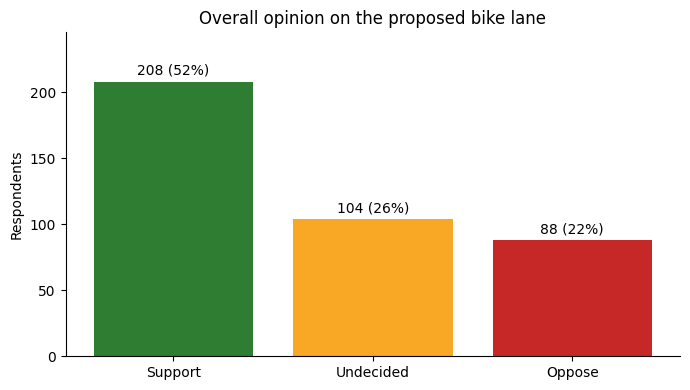

In [2]:
opinion_order = ["Support", "Undecided", "Oppose"]
opinion_colors = ["#2E7D32", "#F9A825", "#C62828"]
opinion_counts = survey["Support_for_New_Bike_Lane"].value_counts().reindex(opinion_order, fill_value=0)
unexpected_opinions = sorted(set(survey["Support_for_New_Bike_Lane"].dropna()) - set(opinion_order))
if unexpected_opinions or survey["Support_for_New_Bike_Lane"].isna().any():
    raise ValueError(f"Unexpected or missing opinion values: {unexpected_opinions}")

opinion_summary = opinion_counts.rename_axis("Opinion").to_frame("Respondents")
opinion_summary["Share of all respondents"] = opinion_summary["Respondents"] / len(survey)
display(opinion_summary.style.format({"Respondents": "{:,.0f}", "Share of all respondents": "{:.1%}"}))
if opinion_counts["Oppose"] == 0:
    raise ValueError("Cannot calculate the support-to-opposition ratio because there are no opposition responses.")
support_to_opposition_ratio = opinion_counts["Support"] / opinion_counts["Oppose"]
print(f"Support-to-opposition ratio (excluding undecided): {support_to_opposition_ratio:.2f}:1 "
      f"({opinion_counts['Support']} support / {opinion_counts['Oppose']} oppose)")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(opinion_counts.index, opinion_counts.values, color=opinion_colors)
for bar, count in zip(bars, opinion_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3,
            f"{count} ({count / len(survey):.0%})", ha="center", va="bottom")
ax.set_ylim(0, opinion_counts.max() * 1.18)
ax.set_ylabel("Respondents")
ax.set_title("Overall opinion on the proposed bike lane")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

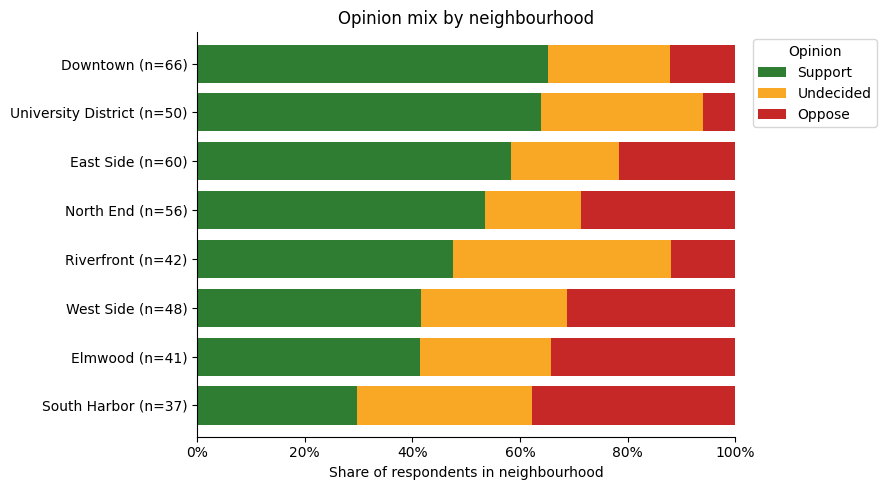

In [3]:
from matplotlib.ticker import PercentFormatter

neighborhood_counts = pd.crosstab(survey["Neighborhood"], survey["Support_for_New_Bike_Lane"])
neighborhood_counts = neighborhood_counts.reindex(columns=opinion_order, fill_value=0)
neighborhood_share = neighborhood_counts.div(neighborhood_counts.sum(axis=1), axis=0)
neighborhood_share = neighborhood_share.sort_values("Support", ascending=True)
neighborhood_labels = [
    f"{name} (n={int(neighborhood_counts.loc[name].sum())})" for name in neighborhood_share.index
]

ax = neighborhood_share.set_axis(neighborhood_labels).plot(
    kind="barh", stacked=True, figsize=(9, 5),
    color=opinion_colors, width=0.78
)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of respondents in neighbourhood")
ax.set_ylabel("")
ax.set_title("Opinion mix by neighbourhood")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend(title="Opinion", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

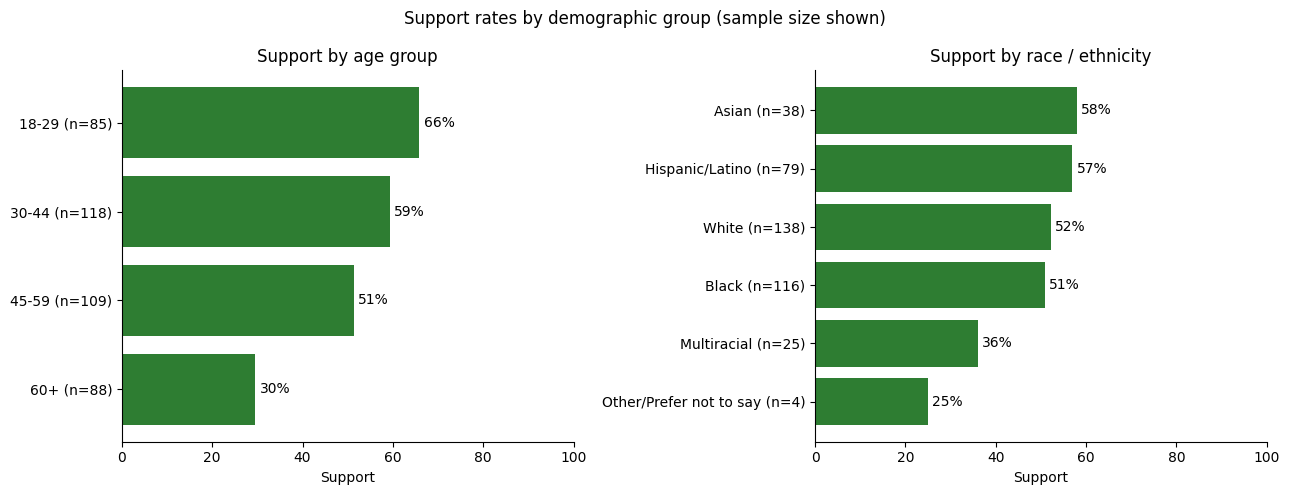

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, column, title in zip(
    axes,
    ["Age_Group", "Race_Ethnicity"],
    ["Support by age group", "Support by race / ethnicity"],
):
    group_counts = pd.crosstab(survey[column], survey["Support_for_New_Bike_Lane"])
    group_counts = group_counts.reindex(columns=opinion_order, fill_value=0)
    group_summary = pd.DataFrame({
        "Support %": group_counts["Support"] / group_counts.sum(axis=1) * 100,
        "n": group_counts.sum(axis=1),
    }).sort_values("Support %", ascending=True)
    labels = [f"{name} (n={int(n)})" for name, n in group_summary["n"].items()]
    bars = ax.barh(labels, group_summary["Support %"], color="#2E7D32")
    ax.bar_label(bars, fmt="%.0f%%", padding=3)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Support")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Support rates by demographic group (sample size shown)")
fig.tight_layout()
plt.show()

## What undecided respondents say they need

The survey records one `Top_Reason_or_Concern` per person. The grouped conditions below combine related response options for a practical summary; the reason-level table keeps the underlying detail visible.

In [5]:
condition_by_reason = {
    "Wants traffic data first": "Evidence and reversibility",
    "Wants pilot before permanent build": "Evidence and reversibility",
    "Needs parking plan": "Parking and curb access",
    "Wants loading zones protected": "Parking and curb access",
    "Concerned about snow removal / maintenance": "Operations and maintenance",
    "Wants bus operations addressed": "Operations and maintenance",
    "Needs stronger intersection design": "Design specifics",
    "Supports concept, unsure about specifics": "Design specifics",
}
undecided["Condition"] = undecided["Top_Reason_or_Concern"].map(condition_by_reason)
if undecided["Condition"].isna().any():
    raise ValueError("An undecided reason is missing from the condition mapping.")

reason_summary = (
    undecided["Top_Reason_or_Concern"].value_counts()
    .rename_axis("Stated top concern")
    .rename("Respondents")
    .to_frame()
)
reason_summary["Share of undecided"] = reason_summary["Respondents"] / len(undecided)
display(reason_summary.style.format({"Share of undecided": "{:.1%}"}))

condition_summary = (
    undecided.groupby("Condition", sort=False)
    .size().rename("Respondents").to_frame()
)
condition_summary["Share of undecided"] = condition_summary["Respondents"] / len(undecided)
condition_summary = condition_summary.sort_values("Respondents", ascending=False)
display(condition_summary.style.format({"Share of undecided": "{:.1%}"}))

,Respondents,Share of undecided
Stated top concern,,
Wants traffic data first,19,18.3%
Needs parking plan,17,16.3%
Concerned about snow removal / maintenance,14,13.5%
Wants loading zones protected,13,12.5%
Wants pilot before permanent build,12,11.5%
Wants bus operations addressed,11,10.6%
"Supports concept, unsure about specifics",10,9.6%
Needs stronger intersection design,8,7.7%


,Respondents,Share of undecided
Condition,,
Evidence and reversibility,31,29.8%
Parking and curb access,30,28.8%
Operations and maintenance,25,24.0%
Design specifics,18,17.3%


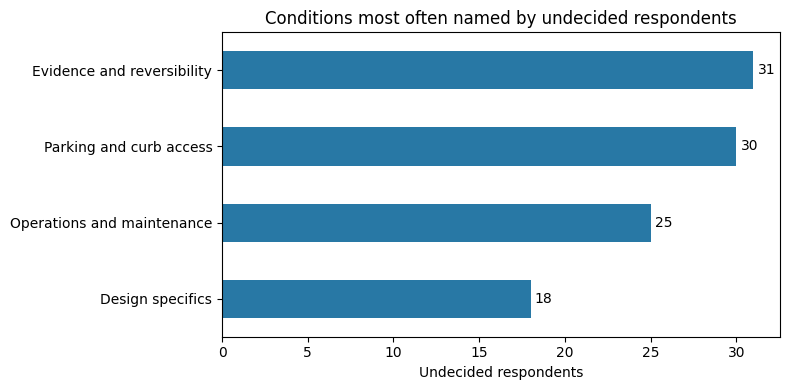

In [6]:
ax = condition_summary["Respondents"].sort_values().plot.barh(figsize=(8, 4), color="#2878A5")
ax.set_xlabel("Undecided respondents")
ax.set_ylabel("")
ax.set_title("Conditions most often named by undecided respondents")
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()

## Ranked concerns and benefits

Concern charts are separated for undecided respondents and opponents because they represent different groups and different kinds of responses. Benefits are shown both as the specific reasons supporters selected and as the workbook's broader benefit themes.

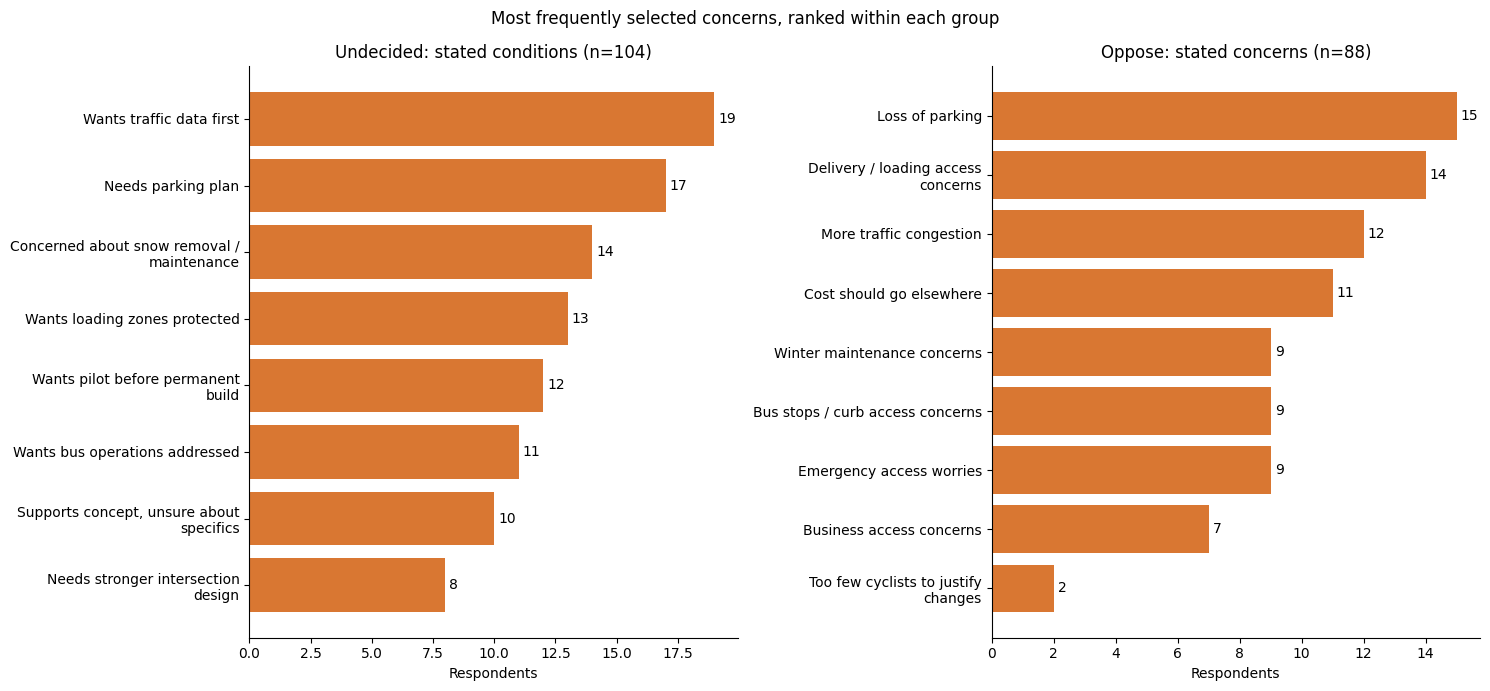

In [7]:
import textwrap

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, opinion, title in zip(
    axes,
    ["Undecided", "Oppose"],
    ["Undecided: stated conditions", "Oppose: stated concerns"],
):
    reason_counts = (
        survey.loc[survey["Support_for_New_Bike_Lane"].eq(opinion), "Top_Reason_or_Concern"]
        .value_counts().sort_values(ascending=True)
    )
    labels = [textwrap.fill(str(reason), width=32) for reason in reason_counts.index]
    bars = ax.barh(labels, reason_counts.values, color="#D97732")
    ax.bar_label(bars, padding=3)
    ax.set_xlabel("Respondents")
    ax.set_title(f"{title} (n={int(reason_counts.sum())})")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Most frequently selected concerns, ranked within each group")
fig.tight_layout()
plt.show()

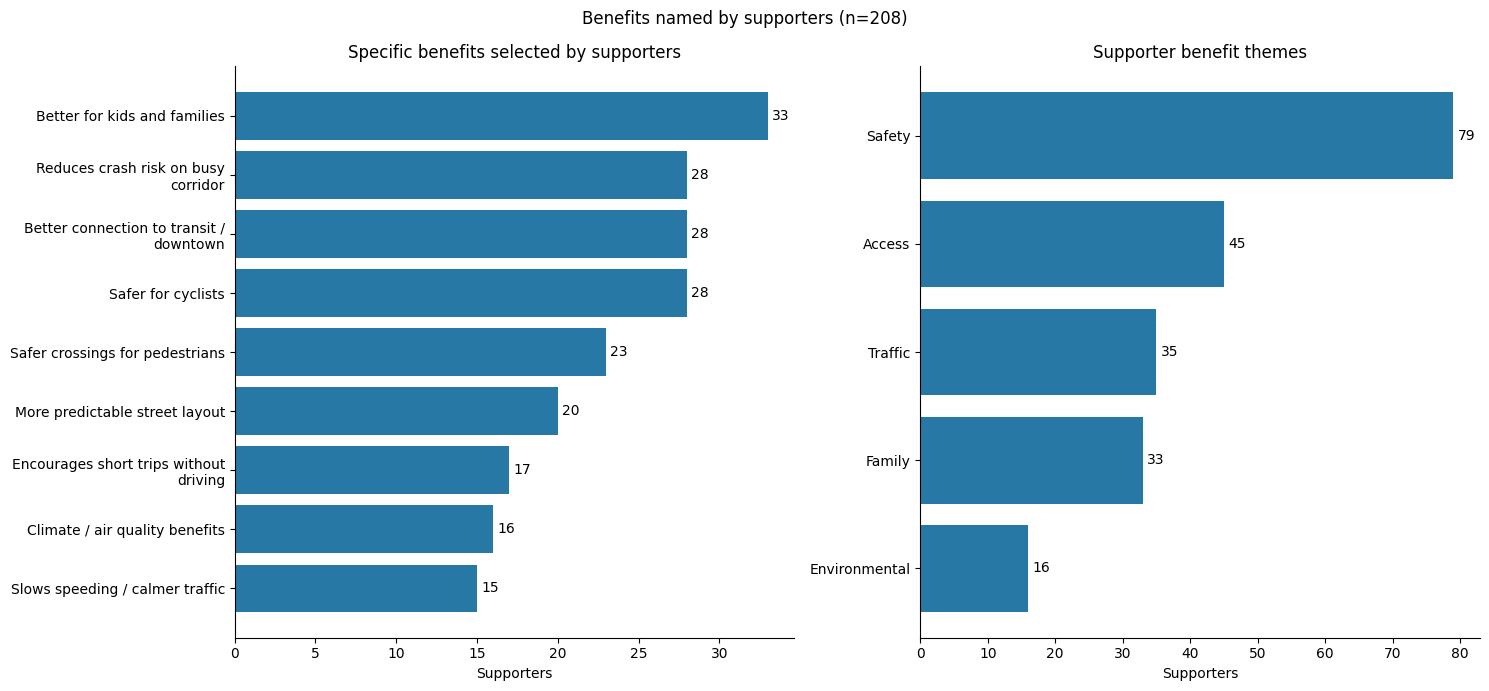

In [8]:
benefits_data = pd.read_excel(DATA_FILE, sheet_name="Support Reasons Data")
specific_benefits = benefits_data["Top_Reason"].value_counts().sort_values(ascending=True)
benefit_themes = benefits_data["Reason_Theme"].value_counts().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, counts, title in zip(
    axes,
    [specific_benefits, benefit_themes],
    ["Specific benefits selected by supporters", "Supporter benefit themes"],
):
    labels = [textwrap.fill(str(label), width=32) for label in counts.index]
    bars = ax.barh(labels, counts.values, color="#2878A5")
    ax.bar_label(bars, padding=3)
    ax.set_xlabel("Supporters")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Benefits named by supporters (n={len(benefits_data)})")
fig.tight_layout()
plt.show()

## Written comments and respondent context

Comments are optional, so they provide examples rather than a representative measure. The profile table is descriptive and should not be read as evidence that a particular demographic or travel group is more persuadable.

In [9]:
comment_examples = (
    undecided.loc[undecided["Open_Ended_Response"].notna(), ["Condition", "Open_Ended_Response"]]
    .groupby("Condition", sort=False, group_keys=False)
    .head(2)
    .rename(columns={"Condition": "Condition", "Open_Ended_Response": "An example comment"})
)
display(comment_examples.reset_index(drop=True))

profile_columns = ["Bike_Rider_Frequency", "Primary_Transportation_Mode", "Uses_Proposed_Corridor_Weekly"]
profile_rows = []
for column in profile_columns:
    counts = undecided[column].value_counts(dropna=False)
    for value, count in counts.items():
        profile_rows.append({"Measure": column, "Response": value, "Respondents": count, "Share of undecided": count / len(undecided)})
profile = pd.DataFrame(profile_rows)
display(profile.style.format({"Share of undecided": "{:.1%}"}))

,Condition,An example comment
0,Operations and maintenance,I am waiting to see how the plan affects bus s...
1,Parking and curb access,I want to see a better curb-management plan be...
2,Operations and maintenance,The bus-stop design could make or break this f...
3,Parking and curb access,I could support this if the city showed a real...
4,Design specifics,"I like the direction, though the exact design ..."
5,Design specifics,"The concept is fine, but the tricky parts are ..."
6,Evidence and reversibility,"Show the likely delay and travel time impacts,..."
7,Evidence and reversibility,I would rather see a pilot first and then judg...


,Measure,Response,Respondents,Share of undecided
0,Bike_Rider_Frequency,Never,50,48.1%
1,Bike_Rider_Frequency,Rarely,29,27.9%
2,Bike_Rider_Frequency,Monthly,20,19.2%
3,Bike_Rider_Frequency,Weekly,5,4.8%
4,Primary_Transportation_Mode,Car,48,46.2%
5,Primary_Transportation_Mode,Walk/Transit,22,21.2%
6,Primary_Transportation_Mode,Mixed,19,18.3%
7,Primary_Transportation_Mode,Bus/Train,13,12.5%
8,Primary_Transportation_Mode,Bike,2,1.9%
9,Uses_Proposed_Corridor_Weekly,Yes,62,59.6%


## Representative verbatim comments

These examples were selected from undecided respondents' written answers to illustrate the recurring conditions above. Wording and punctuation are reproduced exactly from the source; no paraphrasing or silent corrections have been made. Respondent IDs are included for traceability. Written comments were optional, so these quotations are illustrative, not statistically representative.

In [10]:
quote_selection = [
    ("Evidence and reversibility", "BLS-112"),
    ("Evidence and reversibility", "BLS-045"),
    ("Parking and curb access", "BLS-309"),
    ("Parking and curb access", "BLS-062"),
    ("Operations and maintenance", "BLS-243"),
    ("Operations and maintenance", "BLS-233"),
    ("Design specifics", "BLS-158"),
    ("Design specifics", "BLS-135"),
]
quote_ids = [respondent_id for _, respondent_id in quote_selection]
if len(quote_ids) != len(set(quote_ids)):
    raise ValueError("Representative quote IDs must be unique.")

quotes = undecided.set_index("Respondent_ID").reindex(quote_ids)
if quotes["Open_Ended_Response"].isna().any():
    raise ValueError("A selected respondent is missing an open-ended comment.")

quotes = quotes[["Top_Reason_or_Concern", "Open_Ended_Response"]].reset_index()
quotes.insert(1, "Theme", [theme for theme, _ in quote_selection])
quotes = quotes.rename(columns={
    "Respondent_ID": "Respondent ID",
    "Top_Reason_or_Concern": "Stated concern",
    "Open_Ended_Response": "Verbatim quotation",
})
display(quotes)

,Respondent ID,Theme,Stated concern,Verbatim quotation
0,BLS-112,Evidence and reversibility,Wants traffic data first,"Show the likely delay and travel time impacts,..."
1,BLS-045,Evidence and reversibility,Wants pilot before permanent build,I would rather see a pilot first and then judg...
2,BLS-309,Parking and curb access,Needs parking plan,I could support this if the city showed a real...
3,BLS-062,Parking and curb access,Wants loading zones protected,I could get there if the plan preserved workab...
4,BLS-243,Operations and maintenance,Wants bus operations addressed,The bus-stop design could make or break this f...
5,BLS-233,Operations and maintenance,Concerned about snow removal / maintenance,My main question is how this would work in win...
6,BLS-158,Design specifics,Needs stronger intersection design,"The concept is fine, but the tricky parts are ..."
7,BLS-135,Design specifics,"Supports concept, unsure about specifics","I like the direction, though the exact design ..."


## Practical implications

Use the condition table as a checklist for public-facing plan details:

- **Evidence and reversibility:** publish expected traffic/travel-time effects, explain how impacts will be measured, and define what a temporary pilot would evaluate.
- **Parking and curb access:** show a concrete parking and loading plan, including how deliveries and access needs will be handled.
- **Operations and maintenance:** specify snow clearing/ongoing maintenance and show how bus stops, boarding, and curb access will work.
- **Design specifics:** provide intersection-level designs and explain how the chosen layout addresses safety and access concerns.

### Limits

This is a descriptive, cross-sectional survey of 400 people, with 104 undecided respondents. Each person chose one top concern; responses were deliberately different across support, undecided, and oppose categories, so the reason field cannot be used to estimate which condition is more likely to change a person's vote. Only some undecided respondents supplied a written comment. Treat the conditions as topics to address and test through follow-up engagement or a measured pilot, not guaranteed levers of persuasion.